In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.cluster import KMeans,DBSCAN
from sklearn.preprocessing import StandardScaler,OneHotEncoder

In [ ]:
df=pd.read_csv("marketing_campaign.csv",sep='\t')

In [ ]:
df

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [ ]:
df.drop(['ID','Response','Z_CostContact','Z_Revenue'],axis=1,inplace=True)

In [ ]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True, errors="coerce")
latest_date = df["Dt_Customer"].max()
df["Customer_Tenure_Days"] = (latest_date - df["Dt_Customer"]).dt.days

In [ ]:
df.drop(['Dt_Customer'],axis=1,inplace=True)

In [ ]:
df['Age']=2022-df['Year_Birth']

In [ ]:
df.drop('Year_Birth',axis=1,inplace=True)

In [ ]:
marital_map={
    "Married":"Partnered",
    "Together":"Partnered",
    "Divorced":"Single",
    "Widow":"Single",
    "Alone":"Single",
    "Absurd":"Single",
    "YOLO":"Single",
    "Single":"Single",
}

In [ ]:
df['Marital_Status']=df['Marital_Status'].map(marital_map)

In [ ]:
encoder=OneHotEncoder(drop="first",sparse_output=False,handle_unknown="ignore")

In [ ]:
education_map = {
    'Basic': 'Undergraduate',
    '2n Cycle': 'Undergraduate',
    'Graduation': 'Graduate',
    'Master': 'Postgraduate',
    'PhD': 'Postgraduate'
}
df['Education'] = df['Education'].map(education_map)
cats = ['Education', 'Marital_Status']
encoded_features = encoder.fit_transform(df[cats])
encoded_df = pd.DataFrame(
    encoded_features,
    columns=encoder.get_feature_names_out(cats),
    index=df.index
)

df = pd.concat([df.drop(columns=cats), encoded_df], axis=1)


In [ ]:
print("Missing values before imputation:\n", df.isnull().sum()[df.isnull().sum() > 0])
if df['Income'].isnull().any():
    df['Income'] = df['Income'].fillna(df['Income'].median())
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_features, columns=df.columns)
display(df_scaled.head())

Missing values before imputation:
 Income    24
dtype: int64


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,...,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Customer_Tenure_Days,Age,Education_Postgraduate,Education_Undergraduate,Marital_Status_Single
0,0.235696,-0.825218,-0.929894,0.307039,0.983781,1.551577,1.679702,2.462147,1.476500,0.843207,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,1.531185,0.985345,-0.786446,-0.360002,1.346874
1,-0.235454,1.032559,0.906934,-0.383664,-0.870479,-0.636301,-0.713225,-0.650449,-0.631503,-0.729006,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-1.190545,1.235733,-0.786446,-0.360002,1.346874
2,0.773999,-0.825218,-0.929894,-0.798086,0.362723,0.570804,-0.177032,1.345274,-0.146905,-0.038766,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-0.205773,0.317643,-0.786446,-0.360002,-0.742460
3,-1.022355,1.032559,-0.929894,-0.798086,-0.870479,-0.560857,-0.651187,-0.503974,-0.583043,-0.748179,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-1.061881,-1.268149,-0.786446,-0.360002,-0.742460
4,0.241888,1.032559,-0.929894,1.550305,-0.389085,0.419916,-0.216914,0.155164,-0.001525,-0.556446,...,-0.28383,-0.28014,-0.262111,-0.11651,-0.097282,-0.953012,-1.017761,1.271543,-0.360002,-0.742460


In [ ]:
inertia=[]
k_range=range(2,8)
for k in k_range:
    kmeans=KMeans(n_clusters=k,random_state=42, n_init=10)
    kmeans.fit(df_scaled)
    inertia.append(kmeans.inertia_)

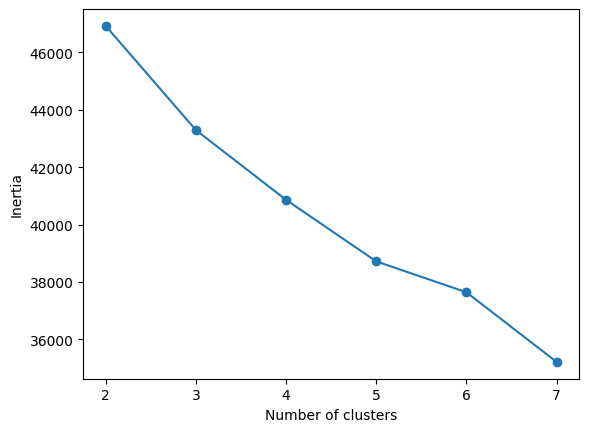

In [ ]:
plt.plot(k_range,inertia,marker="o")
plt.xlabel("Number of clusters")
plt.ylabel("Inertia")
plt.show()

In [ ]:
kmeans_final=KMeans(n_clusters=4,random_state=42)

In [ ]:
cluster_labels=kmeans_final.fit_predict(df_scaled)

In [ ]:
cluster_labels


array([3, 2, 1, ..., 1, 1, 2], dtype=int32)